In [1]:
# === Cell 1: Setup ===
!pip install -q transformers datasets accelerate evaluate

# === Cell 2: Mount Drive ===
from google.colab import drive
drive.mount('/content/drive')

# === Cell 3: Imports + GPU check ===
import os, time
import pandas as pd
import numpy as np
import torch
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback,
)

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device:         {torch.cuda.get_device_name(0)}")
print(f"GPU memory:     {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.9 MB/s eta 0:00:00
Mounted at /content/drive
CUDA available: True
Device:         Tesla T4
GPU memory:     14.6 GB


In [2]:
# === Cell 4: Load data ===
DATA_DIR = "/content/drive/MyDrive/thesis_stage2"
MODEL_NAME = "roberta-base"

df_train = pd.read_csv(f"{DATA_DIR}/patternreframe_train.csv")
df_val   = pd.read_csv(f"{DATA_DIR}/patternreframe_val.csv")
df_test  = pd.read_csv(f"{DATA_DIR}/patternreframe_test.csv")

# Keep only the columns relevant for classification
df_train = df_train[["thought", "pattern"]].copy()
df_val   = df_val[["thought", "pattern"]].copy()
df_test  = df_test[["thought", "pattern"]].copy()

# Drop any rows with missing data (defensive)
df_train = df_train.dropna()
df_val   = df_val.dropna()
df_test  = df_test.dropna()

classes = sorted(df_train["pattern"].unique())
label2id = {label: idx for idx, label in enumerate(classes)}
id2label = {idx: label for label, idx in label2id.items()}

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")
print(f"Classes: {len(classes)}")
print("\nLabel mapping:")
for idx, label in id2label.items():
    print(f"  {idx:>2}  {label}")

Train: 1920, Val: 961, Test: 6807
Classes: 10

Label mapping:
   0  Black-and-white or polarized thinking / All or nothing thinking
   1  Catastrophizing
   2  Discounting the positive
   3  Jumping to conclusions: Fortune-telling
   4  Jumping to conclusions: mind reading
   5  Labeling and mislabeling
   6  Mental filtering
   7  Overgeneralization
   8  Personalization
   9  Should statements


In [3]:
# === Cell 5: Tokenise ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_dataset(df):
    return Dataset.from_pandas(
        df[["thought", "pattern"]]
            .rename(columns={"thought": "text"})
            .assign(label=lambda d: d["pattern"].map(label2id))
            [["text", "label"]],
        preserve_index=False,
    )

raw_datasets = DatasetDict({
    "train":      make_dataset(df_train),
    "validation": make_dataset(df_val),
    "test":       make_dataset(df_test),
})

# Thoughts are short (~25 tokens median), so 256 is more than enough
# and keeps memory footprint low. None will be truncated.
def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

tokenized_datasets = raw_datasets.map(
    tokenize_function, batched=True, remove_columns=["text"]
)

# Quick verification: confirm no truncation actually happened
sample_lengths = [len(x["input_ids"]) for x in tokenized_datasets["train"]]
print(f"Token length stats (training set):")
print(f"  Mean: {np.mean(sample_lengths):.1f}, Max: {max(sample_lengths)}, Min: {min(sample_lengths)}")
print(f"  Records hitting 256-token cap: {sum(1 for l in sample_lengths if l == 256)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1920 [00:00<?, ? examples/s]

Map:   0%|          | 0/961 [00:00<?, ? examples/s]

Map:   0%|          | 0/6807 [00:00<?, ? examples/s]

Token length stats (training set):
  Mean: 23.2, Max: 63, Min: 9
  Records hitting 256-token cap: 0


In [4]:
# === Cell 6: Model + Trainer (NO class weighting — PatternReframe is balanced) ===
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(label2id), id2label=id2label, label2id=label2id,
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
        "f1_macro":    f1_score(labels, predictions, average="macro"),
    }

training_args = TrainingArguments(
    output_dir=f"{DATA_DIR}/roberta_patternreframe_seed42",
    learning_rate=1e-5,            # was 2e-5; matches Maddela
    weight_decay=0.01,
    max_grad_norm=1.0,
    num_train_epochs=10,           # was 5; matches Maddela
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=100,              # was warmup_ratio=0.1; matches Maddela
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    fp16=False,
    bf16=False,
)

trainer = Trainer(
    model=model, args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer, data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [5]:
# === Cell 7: Train ===
start = time.time()
train_result = trainer.train()
print(f"\nTraining finished in {(time.time() - start)/60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.301654,2.277619,0.157128,0.055263,0.054953
2,1.754177,1.354319,0.562955,0.550599,0.556702
3,1.251017,1.250361,0.571280,0.562392,0.568178
4,1.069925,1.223603,0.590010,0.583617,0.589071
5,0.930092,1.209252,0.601457,0.600467,0.605799
6,0.805860,1.246945,0.588970,0.585422,0.590896
7,0.711526,1.257823,0.599376,0.598282,0.603312
8,0.639515,1.262118,0.604579,0.603693,0.608640
9,0.587061,1.270561,0.604579,0.602251,0.607115
10,0.554670,1.277696,0.605619,0.602211,0.607297


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training finished in 5.1 minutes


In [6]:
# === Cell 8: Save final model ===
FINAL_PATH = f"{DATA_DIR}/roberta_patternreframe_final"
trainer.save_model(FINAL_PATH)
tokenizer.save_pretrained(FINAL_PATH)
print(f"Model saved to {FINAL_PATH}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to /content/drive/MyDrive/thesis_stage2/roberta_patternreframe_final


In [7]:
# === Cell 9: Test set evaluation ===
test_predictions = trainer.predict(tokenized_datasets["test"])
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids

print("=== Test set metrics ===")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

print("\n=== Per-category report ===")
print(classification_report(
    y_true, y_pred,
    target_names=[id2label[i] for i in range(len(id2label))],
    digits=3,
))

=== Test set metrics ===
  test_loss: 1.2687
  test_accuracy: 0.6094
  test_f1_weighted: 0.6097
  test_f1_macro: 0.6116
  test_runtime: 16.3941
  test_samples_per_second: 415.2110
  test_steps_per_second: 12.9930

=== Per-category report ===
                                                                 precision    recall  f1-score   support

Black-and-white or polarized thinking / All or nothing thinking      0.603     0.448     0.514       665
                                                Catastrophizing      0.588     0.590     0.589       726
                                       Discounting the positive      0.728     0.673     0.699       681
                        Jumping to conclusions: Fortune-telling      0.378     0.442     0.408       711
                           Jumping to conclusions: mind reading      0.621     0.721     0.668       699
                                       Labeling and mislabeling      0.595     0.555     0.574       669
                      

Saved predictions to /content/drive/MyDrive/thesis_stage2/roberta_patternreframe_test_predictions.csv


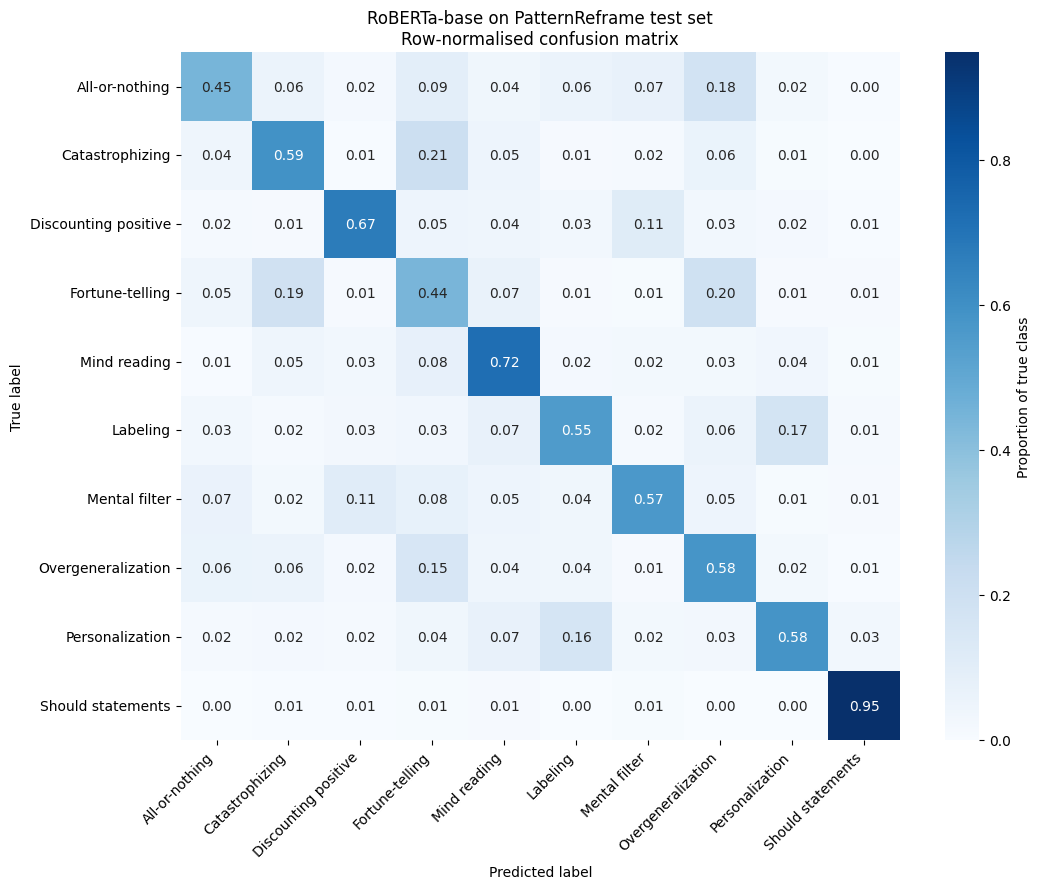

Saved to /content/drive/MyDrive/thesis_stage2/confusion_matrix_patternreframe.png


In [8]:
# === Cell 10: Save predictions and confusion matrix ===
import matplotlib.pyplot as plt
import seaborn as sns

# Save full predictions with class probabilities
predictions_df = pd.DataFrame({
    "y_true":     y_true,
    "y_pred":     y_pred,
    "true_label": [id2label[i] for i in y_true],
    "pred_label": [id2label[i] for i in y_pred],
})
probs = torch.nn.functional.softmax(
    torch.tensor(test_predictions.predictions), dim=-1
).numpy()
for idx in range(len(id2label)):
    predictions_df[f"prob_{idx}"] = probs[:, idx]
predictions_df.to_csv(f"{DATA_DIR}/roberta_patternreframe_test_predictions.csv", index=False)
print(f"Saved predictions to {DATA_DIR}/roberta_patternreframe_test_predictions.csv")

# Short labels for the confusion matrix axes (full names are too long)
short_labels = {
    "Black-and-white or polarized thinking / All or nothing thinking": "All-or-nothing",
    "Catastrophizing":                                                  "Catastrophizing",
    "Discounting the positive":                                         "Discounting positive",
    "Jumping to conclusions: Fortune-telling":                          "Fortune-telling",
    "Jumping to conclusions: mind reading":                             "Mind reading",
    "Labeling and mislabeling":                                         "Labeling",
    "Mental filtering":                                                 "Mental filter",
    "Overgeneralization":                                               "Overgeneralization",
    "Personalization":                                                  "Personalization",
    "Should statements":                                                "Should statements",
}
labels = [id2label[i] for i in range(len(id2label))]
short_axis = [short_labels.get(l, l) for l in labels]

# Row-normalised confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=short_axis, yticklabels=short_axis,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("RoBERTa-base on PatternReframe test set\nRow-normalised confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(f"{DATA_DIR}/confusion_matrix_patternreframe.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved to {DATA_DIR}/confusion_matrix_patternreframe.png")